# EN3160 Assignment 2 - Fitting and Allignment

##### **Name:** Perera U. I. Himal
##### **Index No:** 230486A 
##### **GitHub:** https://github.com/Isira-Himal-Perera/EN3160-Image-Processing-and-Computer-Vision/tree/main/assignment-02

## Question 1 - Blob Detection

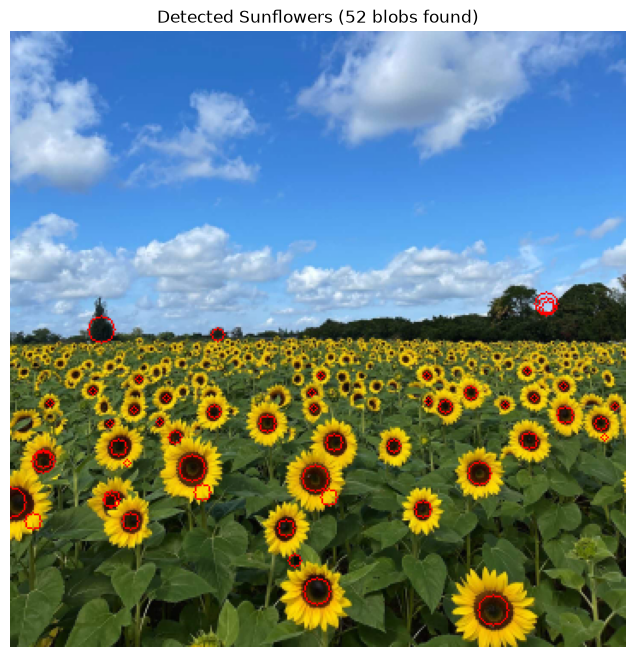

In [1]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

# 1. Load the image as specified in the assignment[cite: 1]
im = cv.imread(
    'images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4
)

# Keep the original color image for drawing, and convert to grayscale for LoG detection
im_gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY)
im_float = im_gray.astype(np.float32) / 255.0

# Define sigma range
# min_sigma = 2.0
# max_sigma = 17.0
# num_sigmas = 18
# sigmas = np.linspace(min_sigma, max_sigma, num_sigmas)

sigmas = np.arange(2, 20)
# Initialize scale-space volume (H, W, num_sigmas)
h, w = im_float.shape
scale_space = np.zeros((h, w, len(sigmas)), dtype=np.float32)

# Build scale-space volume using scale-normalized Laplacian of Gaussian
for i, sigma in enumerate(sigmas):
    ksize = int(2 * np.ceil(3 * sigma) + 1)
    # Ensure kernel size is odd
    if ksize % 2 == 0:
        ksize += 1
    blurred = cv.GaussianBlur(im_float, (ksize, ksize), sigmaX=sigma, sigmaY=sigma)
    laplacian = cv.Laplacian(blurred, cv.CV_32F, ksize=3)
    scale_space[:, :, i] = (sigma**2) * np.abs(laplacian)

# Extract local maxima (blobs) across 3D scale-space (y, x, scale)
blobs = []
threshold = 0.7 * np.max(scale_space)  # Adjusted relative threshold
for i, sigma in enumerate(sigmas):
    slice_curr = scale_space[:, :, i]

    # Find local maxima in the 2D spatial plane using OpenCV morphology dilation
    ksize_morph = int(2 * round(2 * sigma) + 1)
    if ksize_morph % 2 == 0:
        ksize_morph += 1
    kernel = cv.getStructuringElement(cv.MORPH_RECT, (ksize_morph, ksize_morph))
    local_max_xy = cv.dilate(slice_curr, kernel)

    # Get neighboring scales for 3D scale-space comparison
    upper = (scale_space[:, :, i + 1] if i < len(sigmas) - 1 else np.zeros_like(slice_curr))
    lower = scale_space[:, :, i - 1] if i > 0 else np.zeros_like(slice_curr)

    is_max = (
        (slice_curr == local_max_xy)
        & (slice_curr >= upper)
        & (slice_curr >= lower)
        & (slice_curr > threshold)
    )

    y_idxs, x_idxs = np.nonzero(is_max)
    for y, x in zip(y_idxs, x_idxs):
        blobs.append((y, x, sigma))

# Draw circles on a copy of the original color image (OpenCV uses BGR natively)
output_img_bgr = im.copy()

for y, x, sigma in blobs:
    # Radius formula for LoG blob detection: r = sigma * sqrt(2)
    radius = int(sigma * np.sqrt(2))
    cv.circle(output_img_bgr, (x, y), radius, (0, 0, 255), 1)  # Yellow circle (BGR)

# Convert the final output image to RGB format as requested
output_img_rgb = cv.cvtColor(output_img_bgr, cv.COLOR_BGR2RGB)

# Display using matplotlib
plt.figure(figsize=(12, 8))
plt.imshow(output_img_rgb)
plt.axis('off')
plt.title(f'Detected Sunflowers ({len(blobs)} blobs found)')
plt.show()

## Question 2 - RANSAC

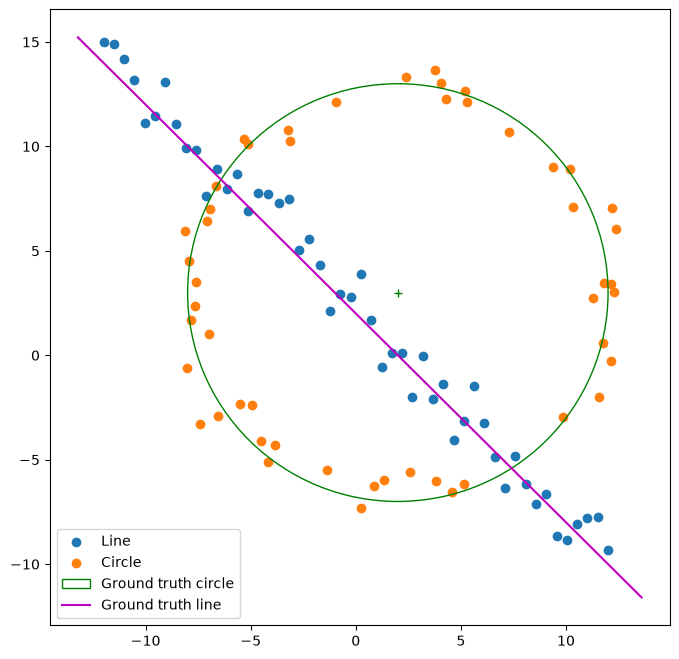

In [2]:
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt

np.random.seed(486)
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3  # Center
s = r / 16
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

s = 1.0
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

X = np.vstack((X_circ, X_line))  # All points
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(X_line[:, 0], X_line[:, 1], label='Line')
ax.scatter(X_circ[:, 0], X_circ[:, 1], label='Circle')

circle_gt = plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle')
ax.add_patch(circle_gt)
ax.plot(x0_gt, y0_gt, '+', color='g')

x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m * x_ + b
plt.plot(x_, y_, color='m', label='Ground truth line')
plt.legend()
plt.show()

### (a) Generating the Line

In [3]:
def fit_line_tls(points):
    # Compute the mean of the points
    mean = np.mean(points, axis=0)
    # Center the points by subtracting the mean
    U = points - mean
    # Compute the scatter/covariance matrix (transpose dot product)
    UtU = np.dot(U.T, U)
    # Perform eigenvalue decomposition on the scatter matrix
    eigenvalues, eigenvectors = np.linalg.eig(UtU)
    # Find the eigenvector corresponding to the smallest eigenvalue (Total Least Squares solution)
    min_idx = np.argmin(eigenvalues)
    normal = eigenvectors[:, min_idx]
    # Normalize the normal vector
    normal = normal / np.linalg.norm(normal)
    a, b = normal[0], normal[1]
    # Compute the line offset d using the mean point
    d = np.dot(normal, mean)
    return a, b, d

def ransac_line(X, num_iterations=1000, threshold=2.0, min_inliers=50):
    best_a, best_b, best_d = None, None, None
    best_inliers = []
    best_sample = None
    max_inliers_count = 0
    N_points = X.shape[0]
    
    for _ in range(num_iterations):
        # Randomly select two points to define a tentative line model
        sample_indices = np.random.choice(N_points, 2, replace=False)
        p1 = X[sample_indices[0]]
        p2 = X[sample_indices[1]]
        
        # Calculate the direction vector and its orthogonal normal vector
        dir_vec = p2 - p1
        normal = np.array([-dir_vec[1], dir_vec[0]])
        norm_val = np.linalg.norm(normal)
        # Skip iteration if the sampled points are too close to each other
        if norm_val < 1e-9:
            continue
        normal = normal / norm_val
        a, b = normal[0], normal[1]
        d = a * p1[0] + b * p1[1]
        
        # Compute perpendicular distances of all points to the candidate line
        distances = np.abs(np.dot(X, np.array([a, b])) - d)
        # Identify points within the distance threshold as inliers
        inlier_indices = np.where(distances < threshold)[0]
        
        # Update the best model if the current inlier count exceeds the previous maximum
        if len(inlier_indices) > max_inliers_count:
            max_inliers_count = len(inlier_indices)
            best_inliers = inlier_indices
            best_a, best_b, best_d = a, b, d
            best_sample = (p1, p2)
            
    # If enough inliers are found, refine the line parameters using Total Least Squares
    if len(best_inliers) >= min_inliers:
        best_a, best_b, best_d = np.real(fit_line_tls(X[best_inliers]))
        
    return best_a, best_b, best_d, best_inliers, best_sample

### (b) generating the circle 

In [4]:
def fit_circle_3points(p1, p2, p3):
    """
    Fits a circle through 3 given points using algebraic circle fitting.
    """
    A_mat = np.array([
        [p1[0], p1[1], 1],
        [p2[0], p2[1], 1],
        [p3[0], p3[1], 1]
    ])
    b_mat = -np.array([
        p1[0]**2 + p1[1]**2,
        p2[0]**2 + p2[1]**2,
        p3[0]**2 + p3[1]**2
    ])
    try:
        params = np.linalg.solve(A_mat, b_mat)
    except np.linalg.LinAlgError:
        return None, None, None
    
    A, B, C = params
    x0 = -A / 2.0
    y0 = -B / 2.0
    r_sq = x0**2 + y0**2 - C
    if r_sq < 0:
        return None, None, None
    r = np.sqrt(r_sq)
    return x0, y0, r

def fit_circle_ls(points):
    """
    Refines circle parameters (center and radius) using least squares optimization.
    """
    x0_init = np.mean(points[:, 0])
    y0_init = np.mean(points[:, 1])
    r_init = np.mean(np.sqrt((points[:, 0] - x0_init)**2 + (points[:, 1] - y0_init)**2))
    
    def objective(params):
        x0, y0, r = params
        distances = np.sqrt((points[:, 0] - x0)**2 + (points[:, 1] - y0)**2)
        return np.sum((distances - r)**2)
        
    res = minimize(objective, [x0_init, y0_init, r_init])
    return res.x[0], res.x[1], res.x[2]

def ransac_circle(X, num_iterations=1000, threshold=2.0, min_inliers=25):
    """
    Estimates a circle from noisy 2D data using the RANSAC algorithm.
    """
    best_x0, best_y0, best_r = None, None, None
    best_inliers = []
    best_sample = None
    max_inliers_count = 0
    N_points = X.shape[0]
    
    if N_points < 3:
        return None, None, None, [], None
        
    for _ in range(num_iterations):
        # Randomly select three points to define a tentative circle model
        sample_indices = np.random.choice(N_points, 3, replace=False)
        p1, p2, p3 = X[sample_indices[0]], X[sample_indices[1]], X[sample_indices[2]]
        
        x0, y0, r = fit_circle_3points(p1, p2, p3)
        if x0 is None:
            continue
            
        # Compute distances of all points to the candidate circle boundary
        distances = np.abs(np.sqrt((X[:, 0] - x0)**2 + (X[:, 1] - y0)**2) - r)
        inlier_indices = np.where(distances < threshold)[0]
        
        # Update the best model if the current inlier count exceeds the previous maximum
        if len(inlier_indices) > max_inliers_count:
            max_inliers_count = len(inlier_indices)
            best_inliers = inlier_indices
            best_x0, best_y0, best_r = x0, y0, r
            best_sample = (p1, p2, p3)
            
    # If enough inliers are found, refine the circle parameters using least squares
    if len(best_inliers) >= min_inliers:
        best_x0, best_y0, best_r = np.real(fit_circle_ls(X[best_inliers]))
        
    return best_x0, best_y0, best_r, best_inliers, best_sample

# Define RANSAC thresholds for line and circle extraction pipeline
line_threshold = 1.5
circle_threshold = 1.25

# Step 1: Detect and fit line inliers from the dataset
a_est, b_est, d_est, line_inliers, line_sample = ransac_line(X, 1000, line_threshold)

# Step 2: Remove line inliers to isolate remaining points for circle fitting
line_mask = np.zeros(X.shape[0], dtype=bool)
line_mask[line_inliers] = True
X_remaining = X[~line_mask]

# Step 3: Detect and fit circle parameters from the remaining points
x0_est, y0_est, r_est, circle_inliers_rel, circle_sample = ransac_circle(X_remaining, 1000, circle_threshold)

# Step 4: Map the circle inliers back to their corresponding indices in the original X array
remaining_indices = np.where(~line_mask)[0]
circle_inliers = remaining_indices[circle_inliers_rel]

### (c) plotting the visualisation

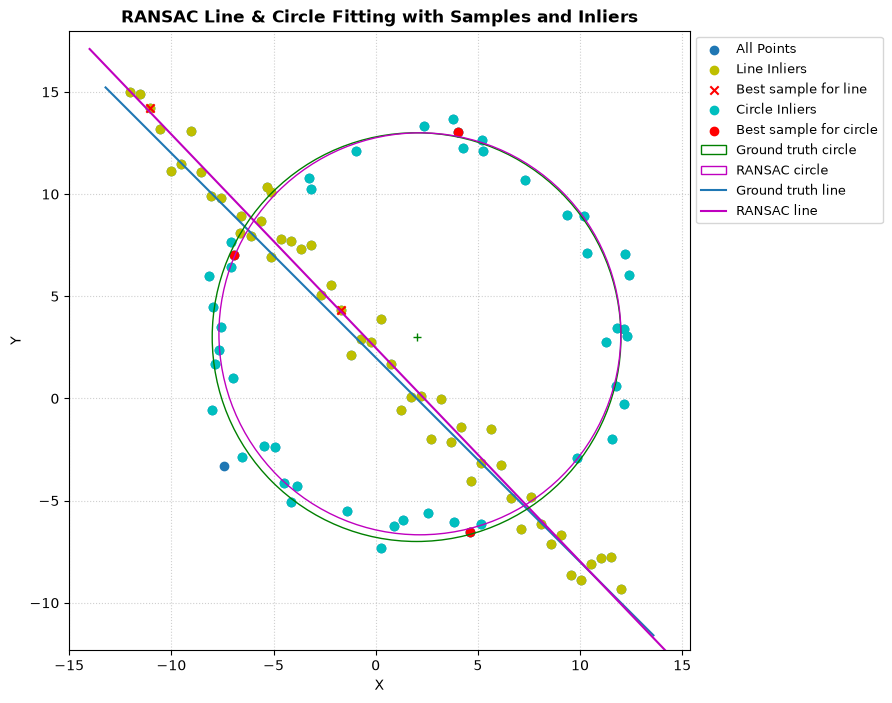

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(9, 9))

# Plot all data points (including outliers)
ax.scatter(X[:, 0], X[:, 1], label='All Points', zorder=1)

if line_sample:
    # Plot detected line inliers
    ax.scatter(X[line_inliers, 0], X[line_inliers, 1], color='y', label='Line Inliers', zorder=2)

    # Plot the best sample points used for line estimation
    line_sample_arr = np.array(line_sample)
    ax.scatter(line_sample_arr[:, 0], line_sample_arr[:, 1], color='r', marker='x', zorder=3, label='Best sample for line')

if circle_sample:
    # Plot detected circle inliers
    ax.scatter(X[circle_inliers, 0], X[circle_inliers, 1], color='c', label='Circle Inliers', zorder=4)

    # Plot the best sample points used for circle estimation
    circle_sample_arr = np.array(circle_sample)
    ax.scatter(circle_sample_arr[:, 0], circle_sample_arr[:, 1], color='r', zorder=5, label='Best sample for circle')

# Plot the ground truth circle and its center
circle_gt = plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle', zorder=6)
ax.add_patch(circle_gt)
ax.plot(x0_gt, y0_gt, '+', color='g')

if circle_sample:
    # Plot the estimated RANSAC circle and its center
    best_circle_patch = plt.Circle((x0_est, y0_est), r_est, fill=False, color='m', label='RANSAC circle', zorder=7)
    ax.add_patch(best_circle_patch)
    ax.plot(x0_est, y0_est, color='m')

# Plot the ground truth line
plt.plot(x_, y_, label='Ground truth line')

if line_sample:
    # Calculate coordinate range to plot the estimated RANSAC line
    x_min, x_max = X[:, 0].min() - 2, X[:, 0].max() + 2
    x_vals = np.array([x_min, x_max])

    if abs(b_est) > 1e-6:   # If not a vertical line
        y_vals = (d_est - a_est * x_vals) / b_est
    else:                   # If a vertical line
        x_vals = np.array([d_est / a_est, d_est / a_est]) # Note: original logic kept intact
        y_vals = np.array([X[:, 1].min() - 2, X[:, 1].max() + 2])

    ax.plot(x_vals, y_vals, color='m', label='RANSAC line', zorder=3)

# Configure plot limits, aspect ratio, grid, and legend layout
ax.set_xlim(X[:, 0].min() - 3, X[:, 0].max() + 3)
ax.set_ylim(X[:, 1].min() - 3, X[:, 1].max() + 3)
ax.set_aspect('equal')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=9)
plt.title("RANSAC Line & Circle Fitting with Samples and Inliers", fontsize=12, fontweight='bold')
plt.xlabel("X")
plt.ylabel("Y")
plt.tight_layout()
plt.show()


### (d) Analysis: What will happen if we fit the circle first?

If we fit the circle first, the circle's RANSAC algorithm will incorrectly capture the segment of the line passing through the interior of the circle—including the intersection points—as circle inliers because they fall within the circle's radial error threshold. 

Consequently, when these inliers are removed to fit the line next, the middle section of the line is deleted. This leaves fragmented, disconnected line segments, which prevents the line-fitting RANSAC algorithm from accurately recovering the true line.

## Question (3) Homography

Please click exactly 4 corners on the image window (press 'q' to abort)...


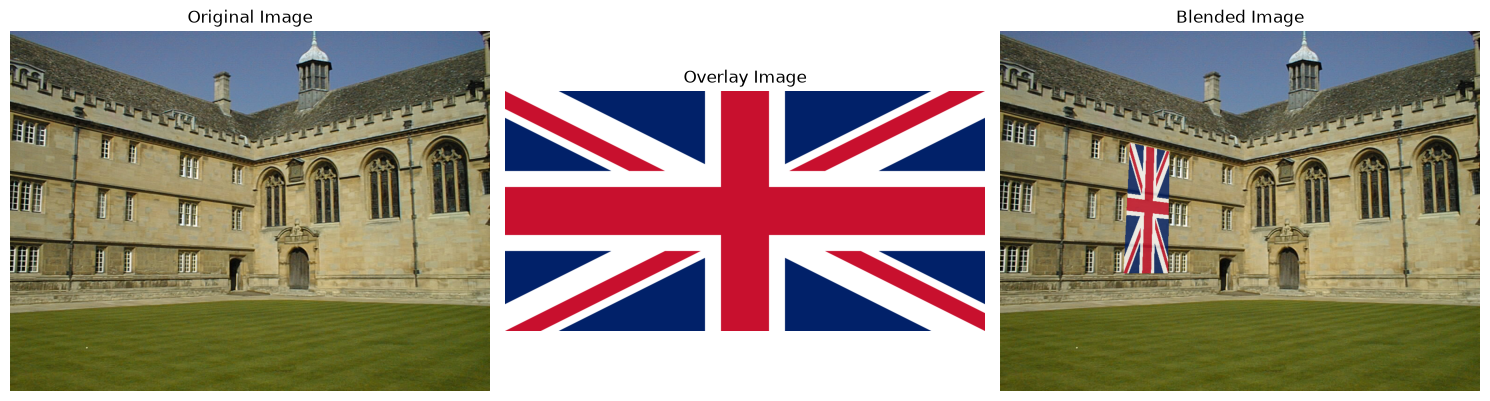

In [ ]:
im1 = cv.imread('images/wadham.jpg', cv.IMREAD_COLOR)
im2 = cv.imread('images/flag.png', cv.IMREAD_COLOR)

assert im1 is not None
assert im2 is not None

h, w = im2.shape[:2]  # Size of the overlay image
corners = []

# 2. Mouse callback function for interactive corner selection
def click_event(event, x, y, flags, params):
    if event == cv.EVENT_LBUTTONDOWN and len(corners) < 4:
        corners.append((x, y))
        # Draw a visual green dot on the display image for feedback
        cv.circle(image_display, (x, y), 5, (0, 255, 0), -1)
        cv.imshow('Select 4 Corners', image_display)

image_display = im1.copy()
cv.imshow('Select 4 Corners', image_display)
cv.setMouseCallback('Select 4 Corners', click_event)  

print("Please click exactly 4 corners on the image window (press 'q' to abort)...")

# Keep window active until 4 points are selected or 'q' is pressed
while True:
    key = cv.waitKey(1) & 0xFF
    if len(corners) == 4 or key == ord('q'):
        break

cv.destroyAllWindows()

# 3. Error correction: Validate that exactly 4 corners were picked
if len(corners) != 4:
    raise ValueError(f"Error: Expected 4 points, but only {len(corners)} were selected. Operation aborted.")

# 4. Compute homography with explicit float32 data types
pts_src = np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], dtype=np.float32)
pts_dst = np.array(corners, dtype=np.float32)

H, status = cv.findHomography(pts_src, pts_dst)
if H is None:
    raise RuntimeError("Error: Failed to compute homography matrix from the selected points.")

# 5. Warp and blend images
im_out = cv.warpPerspective(im2, H, (im1.shape[1], im1.shape[0]))
mask = cv.warpPerspective(np.full((h, w), 255, np.uint8), H, (im1.shape[1], im1.shape[0]))
mask3 = (mask > 0)[..., None]

alpha = 0.8  # Flag blending weight
blended = np.where(
    mask3,
    cv.addWeighted(im1, 1 - alpha, im_out, alpha, 0),
    im1.astype(np.uint8)
)

# 6. Display final blended result via OpenCV
cv.imshow('Blended Image', blended)
cv.waitKey(0)
cv.destroyAllWindows()

# 7. Plot results using Matplotlib
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
titles = ['Original Image', 'Overlay Image', 'Blended Image']
images = [im1, im2, blended]

for ax, im, title in zip(axes, images, titles):
    ax.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [38]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

def run_homography_overlay(im1_path, im2_path, alpha=1.0, max_w=1280, max_h=720):
    """
    Loads base and overlay images, prompts the user to select 4 corners interactively,
    computes the perspective homography, blends the images, and plots the results.
    """
    im1 = cv.imread(im1_path, cv.IMREAD_COLOR)
    im2 = cv.imread(im2_path, cv.IMREAD_COLOR)

    assert im1 is not None, f"Could not load base image from {im1_path}"
    assert im2 is not None, f"Could not load overlay image from {im2_path}"

    # Downsample im1 to HD (max 1280x720) if it's larger, preserving the aspect ratio
    h_orig, w_orig = im1.shape[:2]
    if w_orig > max_w or h_orig > max_h:
        scale = min(max_w / w_orig, max_h / h_orig)
        new_w, new_h = int(w_orig * scale), int(h_orig * scale)
        im1 = cv.resize(im1, (new_w, new_h), interpolation=cv.INTER_AREA)
        print(f"Image downsampled from {w_orig}x{h_orig} to {new_w}x{new_h} to fit HD.")

    h, w = im2.shape[:2]  # Size of the overlay image
    corners = []

    # 2. Mouse callback function for interactive corner selection
    def click_event(event, x, y, flags, params):
        if event == cv.EVENT_LBUTTONDOWN and len(corners) < 4:
            corners.append((x, y))
            # Draw a visual green dot on the display image for feedback
            cv.circle(image_display, (x, y), 5, (0, 255, 0), -1)
            cv.imshow('Select 4 Corners', image_display)

    image_display = im1.copy()
    cv.imshow('Select 4 Corners', image_display)
    cv.setMouseCallback('Select 4 Corners', click_event)  

    print("Please click exactly 4 corners on the image window (press 'q' to abort)...")

    # Keep window active until 4 points are selected or 'q' is pressed
    while True:
        key = cv.waitKey(1) & 0xFF
        if len(corners) == 4 or key == ord('q'):
            break

    cv.destroyAllWindows()

    # 3. Error correction: Validate that exactly 4 corners were picked
    if len(corners) != 4:
        raise ValueError(f"Error: Expected 4 points, but only {len(corners)} were selected. Operation aborted.")

    # 4. Compute homography with explicit float32 data types
    pts_src = np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], dtype=np.float32)
    pts_dst = np.array(corners, dtype=np.float32)

    H, status = cv.findHomography(pts_src, pts_dst)
    if H is None:
        raise RuntimeError("Error: Failed to compute homography matrix from the selected points.")

    # 5. Warp and blend images
    im_out = cv.warpPerspective(im2, H, (im1.shape[1], im1.shape[0]))
    mask = cv.warpPerspective(np.full((h, w), 255, np.uint8), H, (im1.shape[1], im1.shape[0]))
    mask3 = (mask > 0)[..., None]

    blended = np.where(
        mask3,
        cv.addWeighted(im1, 1 - alpha, im_out, alpha, 0),
        im1.astype(np.uint8)
    )

    # 6. Display final blended result via OpenCV
    cv.imshow('Blended Image', blended)
    cv.waitKey(0)
    cv.destroyAllWindows()

    # 7. Plot results using Matplotlib
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    titles = ['Original Image', 'Overlay Image', 'Blended Image']
    images = [im1, im2, blended]

    for ax, im, title in zip(axes, images, titles):
        ax.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis('off')

    plt.tight_layout()
    plt.show()
    
    return blended

Image downsampled from 1024x768 to 960x720 to fit HD.
Please click exactly 4 corners on the image window (press 'q' to abort)...


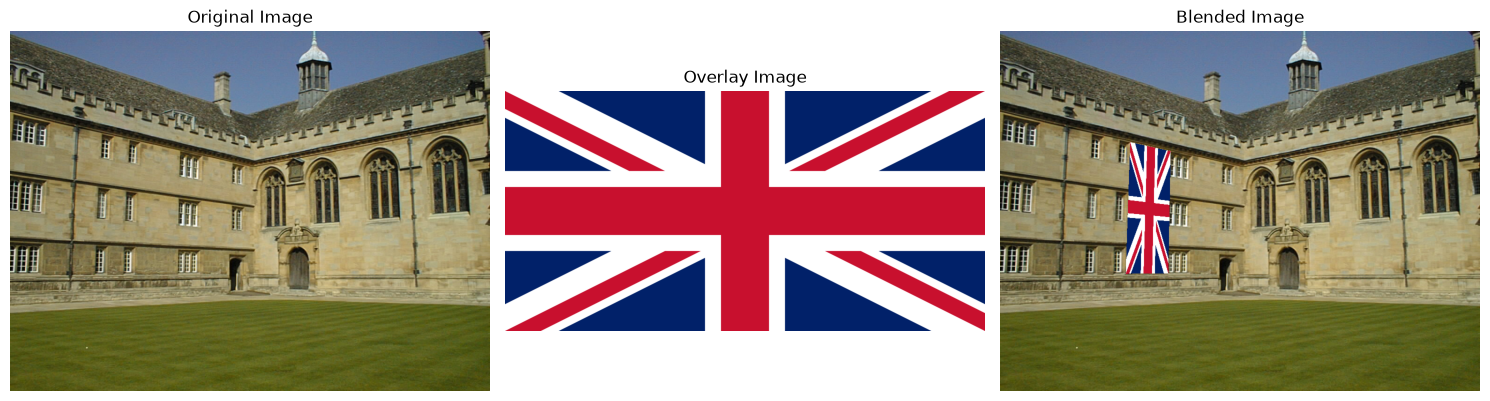

In [ ]:
result_image = run_homography_overlay(
    im1_path='images/wadham.jpg', 
    im2_path='images/flag.png' 
)

Image downsampled from 5000x3337 to 1078x720 to fit HD.
Please click exactly 4 corners on the image window (press 'q' to abort)...


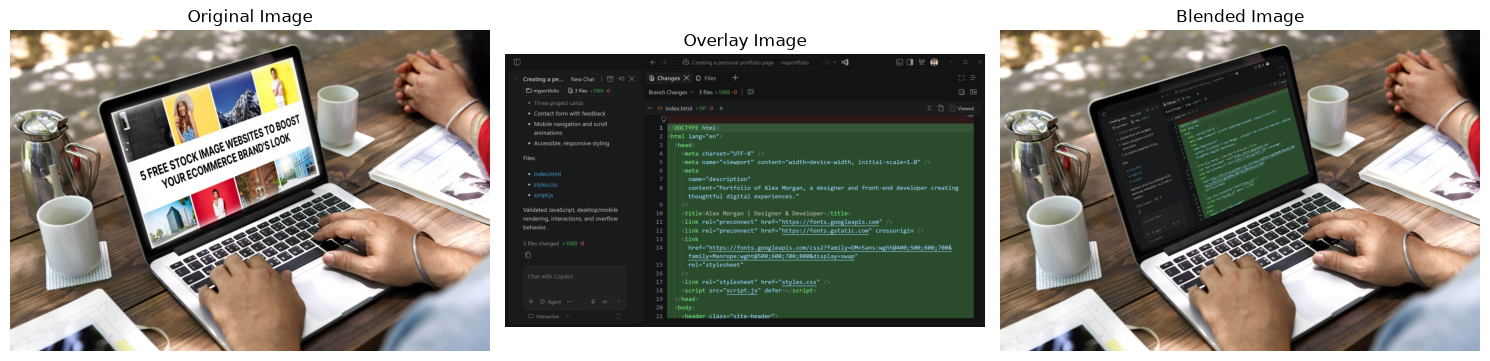

In [47]:
result_image = run_homography_overlay(
    im1_path='images/Free-Stock-Image-Websites.jpg', 
    im2_path='images/changes-panel.png'
)